In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
url = "https://raw.githubusercontent.com/SayaligShinde/Walmart/main/Walmart.csv"
df = pd.read_csv(url)

In [ ]:
df.head()

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin
0,1,WALM003,San Antonio,Health and beauty,$74.69,7.0,05/01/19,13:08:00,Ewallet,9.1,0.48
1,2,WALM048,Harlingen,Electronic accessories,$15.28,5.0,08/03/19,10:29:00,Cash,9.6,0.48
2,3,WALM067,Haltom City,Home and lifestyle,$46.33,7.0,03/03/19,13:23:00,Credit card,7.4,0.33
3,4,WALM064,Bedford,Health and beauty,$58.22,8.0,27/01/19,20:33:00,Ewallet,8.4,0.33
4,5,WALM013,Irving,Sports and travel,$86.31,7.0,08/02/19,10:37:00,Ewallet,5.3,0.48


In [ ]:
df.shape

(10051, 11)

In [ ]:
df.columns

Index(['invoice_id', 'Branch', 'City', 'category', 'unit_price', 'quantity',
       'date', 'time', 'payment_method', 'rating', 'profit_margin'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10051 entries, 0 to 10050
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_id      10051 non-null  int64  
 1   Branch          10051 non-null  object 
 2   City            10051 non-null  object 
 3   category        10051 non-null  object 
 4   unit_price      10020 non-null  object 
 5   quantity        10020 non-null  float64
 6   date            10051 non-null  object 
 7   time            10051 non-null  object 
 8   payment_method  10051 non-null  object 
 9   rating          10051 non-null  float64
 10  profit_margin   10051 non-null  float64
dtypes: float64(3), int64(1), object(7)
memory usage: 863.9+ KB


In [ ]:
df.describe()

,invoice_id,quantity,rating,profit_margin
count,10051.000000,10020.000000,10051.000000,10051.000000
mean,5025.741220,2.353493,5.825659,0.393791
std,2901.174372,1.602658,1.763991,0.090669
min,1.000000,1.000000,3.000000,0.180000
25%,2513.500000,1.000000,4.000000,0.330000
50%,5026.000000,2.000000,6.000000,0.330000
75%,7538.500000,3.000000,7.000000,0.480000
max,10000.000000,10.000000,10.000000,0.570000


In [ ]:
df.isnull().sum()

,0
invoice_id,0
Branch,0
City,0
category,0
unit_price,31
quantity,31
date,0
time,0
payment_method,0
rating,0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 51


In [ ]:
df[df.duplicated(keep=False)].sort_values("invoice_id").head(10)

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin
9949,9950,WALM038,Sugar Land,Fashion accessories,$17,1.0,27/11/23,9:15:00,Cash,3.0,0.48
10000,9950,WALM038,Sugar Land,Fashion accessories,$17,1.0,27/11/23,9:15:00,Cash,3.0,0.48
10001,9951,WALM082,Weslaco,Home and lifestyle,$58,2.0,08/07/20,12:39:00,Cash,6.0,0.33
9950,9951,WALM082,Weslaco,Home and lifestyle,$58,2.0,08/07/20,12:39:00,Cash,6.0,0.33
9951,9952,WALM035,San Angelo,Fashion accessories,$76,3.0,02/10/21,16:34:00,Cash,6.0,0.48
10002,9952,WALM035,San Angelo,Fashion accessories,$76,3.0,02/10/21,16:34:00,Cash,6.0,0.48
10003,9953,WALM084,Schertz,Home and lifestyle,$68,3.0,13/06/21,10:52:00,Cash,5.0,0.33
9952,9953,WALM084,Schertz,Home and lifestyle,$68,3.0,13/06/21,10:52:00,Cash,5.0,0.33
9953,9954,WALM046,Temple,Fashion accessories,$40,1.0,22/08/20,14:38:00,Cash,6.0,0.48
10004,9954,WALM046,Temple,Fashion accessories,$40,1.0,22/08/20,14:38:00,Cash,6.0,0.48


In [ ]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (10000, 11)


In [ ]:
df[df["unit_price"].isna() | df["quantity"].isna()].head(10)

,invoice_id,Branch,City,category,unit_price,quantity,date,time,payment_method,rating,profit_margin
1892,1893,WALM024,Carrollton,Home and lifestyle,NaN,NaN,09/06/23,16:09:00,Ewallet,9.0,0.48
1893,1894,WALM009,Plano,Fashion accessories,NaN,NaN,02/08/22,22:11:00,Ewallet,4.0,0.48
1894,1895,WALM010,Laredo,Home and lifestyle,NaN,NaN,01/08/23,12:06:00,Ewallet,4.0,0.48
1895,1896,WALM069,Rockwall,Fashion accessories,NaN,NaN,21/07/23,15:49:00,Ewallet,4.0,0.33
1896,1897,WALM093,Angleton,Home and lifestyle,NaN,NaN,15/05/22,12:36:00,Ewallet,9.0,0.33
1897,1898,WALM098,Mineral Wells,Fashion accessories,NaN,NaN,01/11/23,10:08:00,Ewallet,4.0,0.18
1898,1899,WALM009,Plano,Home and lifestyle,NaN,NaN,01/10/21,13:05:00,Ewallet,6.0,0.48
1899,1900,WALM071,Lufkin,Fashion accessories,NaN,NaN,19/05/21,8:36:00,Ewallet,7.0,0.33
1900,1901,WALM090,Brownwood,Home and lifestyle,NaN,NaN,13/02/21,14:50:00,Ewallet,8.0,0.33
1901,1902,WALM067,Haltom City,Fashion accessories,NaN,NaN,15/05/22,19:20:00,Ewallet,8.0,0.33


In [ ]:
print("Missing unit_price:", df["unit_price"].isna().sum())
print("Missing quantity:", df["quantity"].isna().sum())
print("Missing in both:", (df["unit_price"].isna() & df["quantity"].isna()).sum())

Missing unit_price: 31
Missing quantity: 31
Missing in both: 31


In [ ]:
df=df.copy()

In [ ]:
df["unit_price"] = pd.to_numeric(
    df["unit_price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False),
    errors="coerce"
)

In [ ]:
print(df["unit_price"].dtype)
print("Missing prices:", df["unit_price"].isna().sum())

float64
Missing prices: 31


In [ ]:
df["date"] = pd.to_datetime(
    df["date"],
    format="%d/%m/%y",
    errors="coerce"
)

In [ ]:
print(df["date"].dtype)
print("Missing dates:", df["date"].isna().sum())

datetime64[ns]
Missing dates: 0


In [ ]:
print("Missing in both:", (df["unit_price"].isna() & df["quantity"].isna()).sum())
print("Missing only in price:", (df["unit_price"].isna() & df["quantity"].notna()).sum())
print("Missing only in quantity:", (df["unit_price"].notna() & df["quantity"].isna()).sum())

Missing in both: 31
Missing only in price: 0
Missing only in quantity: 0


In [ ]:
df = df.dropna(subset=["unit_price", "quantity"]).copy()
print("Dataset shape after cleaning:", df.shape)
print("Missing values:\n", df[["unit_price", "quantity"]].isnull().sum())

Dataset shape after cleaning: (9969, 11)
Missing values:
 unit_price    0
quantity      0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate invoice IDs:", df["invoice_id"].duplicated().sum())

Duplicate rows: 0
Duplicate invoice IDs: 0


In [ ]:
print("Current rows and columns:", df.shape)
print("Missing values in all columns:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Invalid dates:", df["date"].isna().sum())
print("Unit price data type:", df["unit_price"].dtype)
print("Quantity data type:", df["quantity"].dtype)

Current rows and columns: (9969, 11)
Missing values in all columns:
 invoice_id        0
Branch            0
City              0
category          0
unit_price        0
quantity          0
date              0
time              0
payment_method    0
rating            0
profit_margin     0
dtype: int64
Duplicate rows: 0
Date range: 2019-01-01 00:00:00 to 2023-12-31 00:00:00
Invalid dates: 0
Unit price data type: float64
Quantity data type: float64


In [ ]:
print("Non-whole quantity values:", (df["quantity"] % 1 != 0).sum())

Non-whole quantity values: 0


In [ ]:
df["quantity"] = df["quantity"].astype(int)

In [ ]:
print("Number of branches:", df["Branch"].nunique())
print("Cities:", df["City"].unique())
print("Number of product categories:", df["category"].nunique())
print("\nProduct categories:\n", df["category"].value_counts())
print("\nPayment methods:\n", df["payment_method"].value_counts())
print("\nBranch distribution:\n", df["Branch"].value_counts())

Number of branches: 100
Cities: ['San Antonio' 'Harlingen' 'Haltom City' 'Bedford' 'Irving' 'Denton'
 'Cleburne' 'Canyon' 'Grapevine' 'Texas City' 'San Angelo' 'Abilene'
 'Lewisville' 'Corpus Christi' 'Round Rock' 'Cedar Park' 'Conroe' 'Pharr'
 'Farmers Branch' 'Midland' 'Houston' 'Lancaster' 'Temple' 'Garland'
 'San Marcos' 'Huntsville' 'Mineral Wells' 'McAllen' 'Eagle Pass'
 'Mesquite' 'Big Spring' 'Mission' 'Hurst' 'Richardson' 'Pearland'
 'La Porte' 'Bryan' 'Allen' 'Rowlett' 'Port Arthur' 'Grand Prairie'
 'Georgetown' 'Southlake' 'Angleton' 'Missouri City' 'Fort Worth'
 'Del Rio' 'League City' 'Rockwall' 'Waxahachie' 'Killeen' 'Arlington'
 'McKinney' 'Alamo' 'Lufkin' 'Brownwood' 'Alice' 'Baytown' 'Lubbock'
 'North Richland Hills' 'Edinburg' 'College Station' 'Amarillo' 'Austin'
 'Euless' 'Sugar Land' 'Waco' 'Carrollton' 'Kerrville' 'Brownsville'
 'Frisco' 'Burleson' 'Dallas' 'Galveston' 'Mansfield' 'Flower Mound'
 'Sherman' 'Weatherford' 'Weslaco' 'Odessa' 'Pasadena' 'Schertz'
 'Lo

In [ ]:
df["sales"] = df["unit_price"] * df["quantity"]
print(df[["unit_price", "quantity", "sales"]].head())
print("\nTotal sales revenue:", round(df["sales"].sum(), 2))

   unit_price  quantity   sales
0       74.69         7  522.83
1       15.28         5   76.40
2       46.33         7  324.31
3       58.22         8  465.76
4       86.31         7  604.17

Total sales revenue: 1209726.38


In [ ]:
category_sales = df.groupby("category").agg(
    Total_Sales=("sales", "sum"),
    Total_Quantity=("quantity", "sum"),
    Number_of_Transactions=("invoice_id", "count")
).reset_index()
category_sales = category_sales.sort_values(by="Total_Sales", ascending=False)
category_sales["Total_Sales"] = category_sales["Total_Sales"].round(2)
print(category_sales)

                 category  Total_Sales  Total_Quantity  Number_of_Transactions
1     Fashion accessories    489480.90            9653                    4538
4      Home and lifestyle    489250.06            9610                    4520
0  Electronic accessories     78175.03            1494                     419
2      Food and beverages     53471.28             952                     174
5       Sports and travel     52497.93             920                     166
3       Health and beauty     46851.18             854                     152


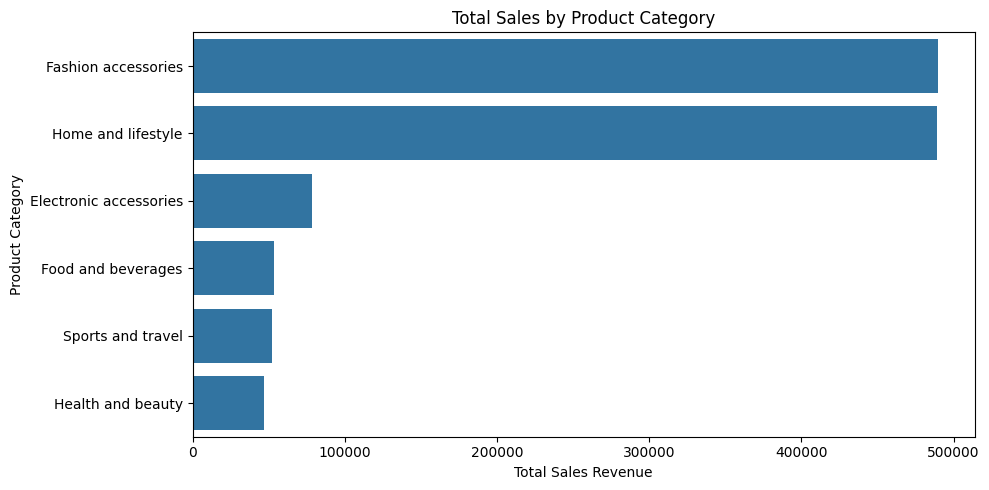

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=category_sales, x="Total_Sales", y="category")
plt.title("Total Sales by Product Category")
plt.xlabel("Total Sales Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

In [ ]:
df["year_month"] = df["date"].dt.to_period("M")
monthly_sales = df.groupby("year_month")["sales"].sum().reset_index()
monthly_sales["year_month"] = monthly_sales["year_month"].astype(str)
monthly_sales = monthly_sales.sort_values("year_month")
print(monthly_sales.to_string(index=False))

year_month     sales
   2019-01 110754.16
   2019-02  92589.88
   2019-03 104243.34
   2020-01   6771.00
   2020-02   7035.00
   2020-03   6188.00
   2020-04   7218.00
   2020-05   8548.00
   2020-06   5434.00
   2020-07   6880.00
   2020-08  16817.00
   2020-09  15345.00
   2020-10  18258.00
   2020-11  60146.00
   2020-12  60783.00
   2021-01   7568.00
   2021-02   8000.00
   2021-03   7494.00
   2021-04   6378.00
   2021-05   7028.00
   2021-06   6395.00
   2021-07   8367.00
   2021-08  16683.00
   2021-09  17787.00
   2021-10  20793.00
   2021-11  59628.00
   2021-12  66930.00
   2022-01   5679.00
   2022-02   8476.00
   2022-03   7108.00
   2022-04   5593.00
   2022-05   7789.00
   2022-06   6356.00
   2022-07   6895.00
   2022-08  16788.00
   2022-09  14808.00
   2022-10  17414.00
   2022-11  61687.00
   2022-12  58812.00
   2023-01   6709.00
   2023-02   6567.00
   2023-03   6659.00
   2023-04   6079.00
   2023-05   7976.00
   2023-06   7460.00
   2023-07   6938.00
   2023-08  1

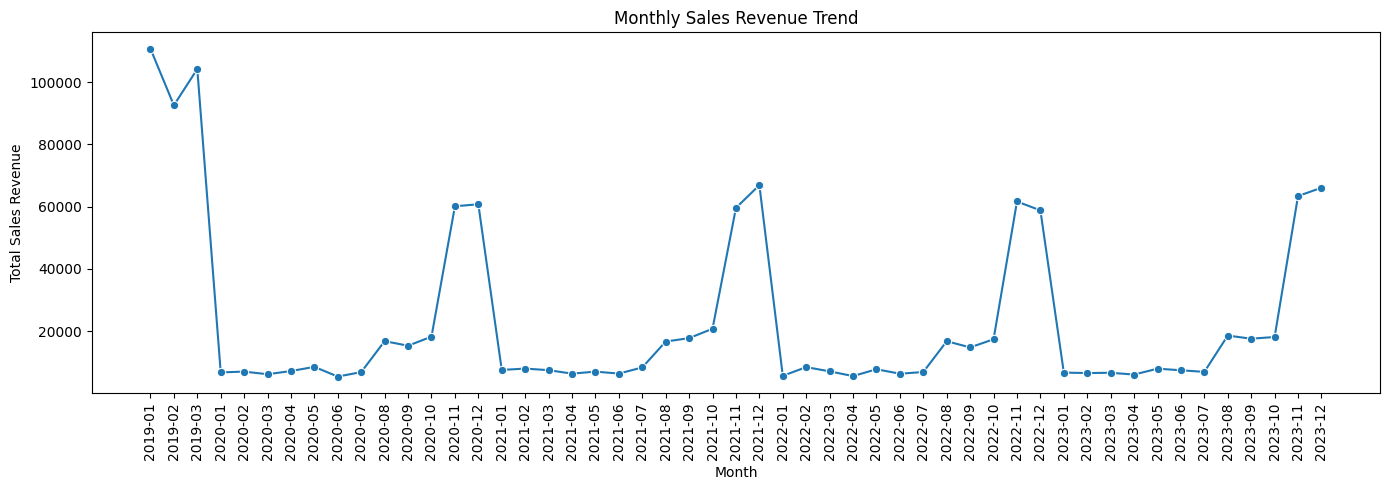

In [ ]:
plt.figure(figsize=(14, 5))
sns.lineplot(data=monthly_sales, x="year_month", y="sales", marker="o")
plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Revenue")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()

complete_years = df[df["year"].between(2020, 2023)]

monthly_comparison = (
    complete_years.groupby(["month", "month_name"])["sales"]
    .mean()
    .reset_index()
    .sort_values("month")
)

monthly_comparison.columns = [
    "Month_Number", "Month", "Average_Monthly_Sales"
]

print(monthly_comparison.round(2).to_string(index=False))

 Month_Number     Month  Average_Monthly_Sales
            1   January                  96.14
            2  February                 107.42
            3     March                  99.09
            4     April                  91.88
            5       May                 107.70
            6      June                  99.40
            7      July                  97.91
            8    August                 101.46
            9 September                 100.22
           10   October                 102.77
           11  November                 100.82
           12  December                 100.05


In [ ]:
# Calculate total sales for each individual month
monthly_totals = (
    df[df["year"].between(2020, 2023)]
    .groupby(["year", "month", "month_name"])["sales"]
    .sum()
    .reset_index()
)

# Calculate average monthly revenue across the four years
monthly_comparison = (
    monthly_totals.groupby(["month", "month_name"])["sales"]
    .mean()
    .reset_index()
    .sort_values("month")
)

monthly_comparison.columns = [
    "Month_Number",
    "Month",
    "Average_Monthly_Revenue"
]

print(monthly_comparison.round(2).to_string(index=False))

 Month_Number     Month  Average_Monthly_Revenue
            1   January                  6681.75
            2  February                  7519.50
            3     March                  6862.25
            4     April                  6317.00
            5       May                  7835.25
            6      June                  6411.25
            7      July                  7270.00
            8    August                 17223.50
            9 September                 16385.75
           10   October                 18653.00
           11  November                 61221.25
           12  December                 63154.25


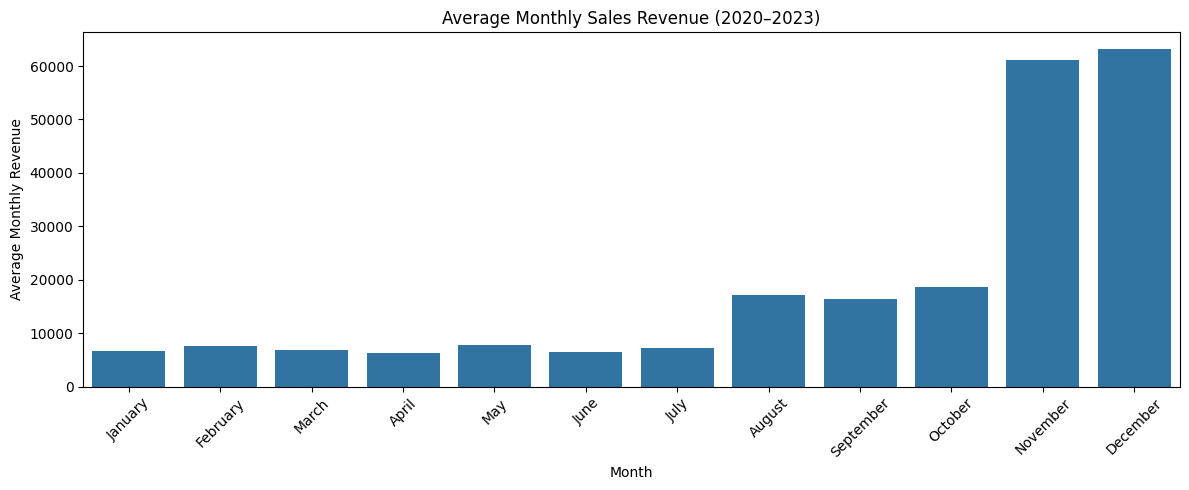

In [ ]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_comparison,
    x="Month",
    y="Average_Monthly_Revenue"
)

plt.title("Average Monthly Sales Revenue (2020–2023)")
plt.xlabel("Month")
plt.ylabel("Average Monthly Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
branch_sales = (
    df.groupby(["Branch", "City"])
    .agg(
        Total_Sales=("sales", "sum"),
        Total_Quantity=("quantity", "sum"),
        Transactions=("invoice_id", "count")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

print("Top 10 branches by sales:")
print(branch_sales.head(10).round(2).to_string(index=False))

print("\nBottom 10 branches by sales:")
print(branch_sales.tail(10).round(2).to_string(index=False))

Top 10 branches by sales:
 Branch        City  Total_Sales  Total_Quantity  Transactions
WALM009       Plano     25688.34             502           235
WALM074     Weslaco     25555.42             473           210
WALM003 San Antonio     24950.56             467           186
WALM058 Port Arthur     24524.37             495           239
WALM030  Richardson     24460.60             489           229
WALM069    Rockwall     24077.70             504           222
WALM029  Round Rock     23327.34             452           196
WALM084     Schertz     23095.43             451           205
WALM075  San Marcos     22124.51             429           188
WALM089   Southlake     21267.06             418           182

Bottom 10 branches by sales:
 Branch         City  Total_Sales  Total_Quantity  Transactions
WALM097        Alice      7376.91             161            67
WALM041      Mission      7327.06             144            67
WALM018       Frisco      7233.95             149          

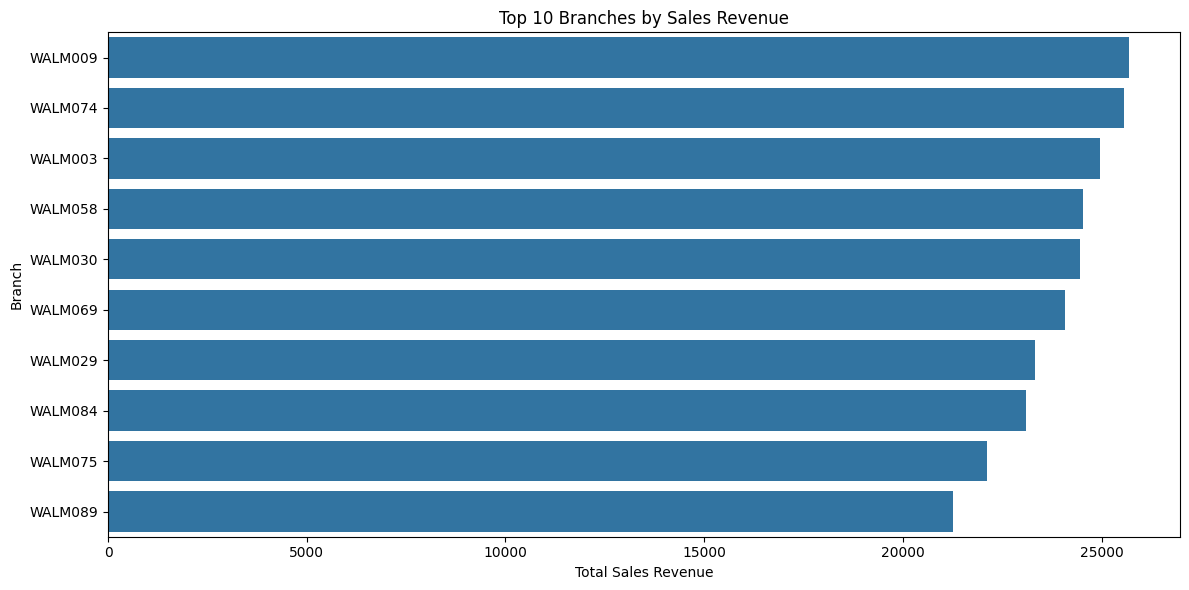

In [ ]:
top_branches = branch_sales.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_branches, x="Total_Sales", y="Branch")
plt.title("Top 10 Branches by Sales Revenue")
plt.xlabel("Total Sales Revenue")
plt.ylabel("Branch")
plt.tight_layout()
plt.show()

In [ ]:
payment_analysis = (
    df.groupby("payment_method")
    .agg(
        Total_Sales=("sales", "sum"),
        Transactions=("invoice_id", "count"),
        Total_Quantity=("quantity", "sum")
    )
    .reset_index()
)

payment_analysis["Sales_Per_Transaction"] = (
    payment_analysis["Total_Sales"] / payment_analysis["Transactions"]
)

payment_analysis = payment_analysis.sort_values(
    "Total_Sales", ascending=False
)

print(payment_analysis.round(2).to_string(index=False))

payment_method  Total_Sales  Transactions  Total_Quantity  Sales_Per_Transaction
   Credit card    488821.02          4256            9567                 114.85
       Ewallet    457316.07          3881            8932                 117.83
          Cash    263589.29          1832            4984                 143.88


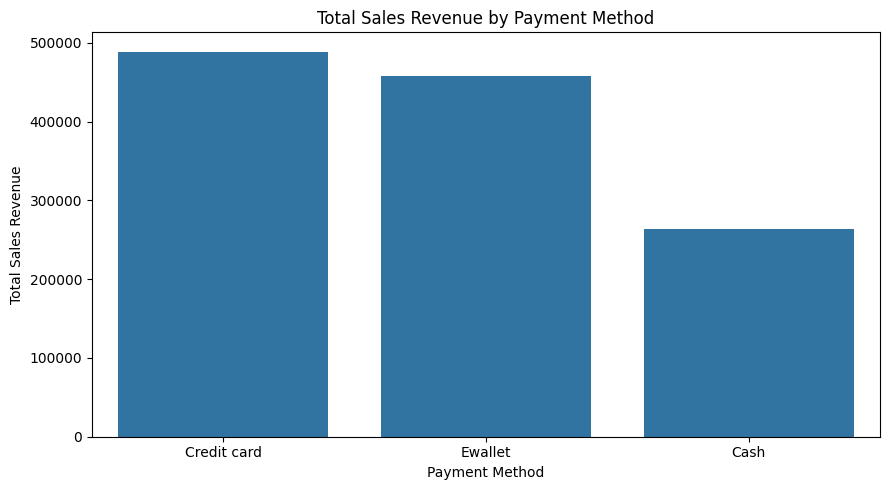

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_analysis,
    x="payment_method",
    y="Total_Sales"
)

plt.title("Total Sales Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales Revenue")
plt.tight_layout()
plt.show()

In [ ]:
df.to_csv("walmart_cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")
print("Rows and columns:", df.shape)

Cleaned dataset exported successfully!
Rows and columns: (9969, 16)
